# Incremental MeshA*: движение и раскрытие карты

Все 15 C++ методов; n = k; одинаковое ограничение обеих сторон обмена. Полный grid8-протокол содержит 36 k/cr на десяти картах; дополнительная car16-динамика содержит четыре заранее выбранные опорные пары на шести картах. Статическое раскрытие содержит четыре радиуса на шести car16-картах. Пары времени требуют общей цели, а online — фактических фаз и ненулевого ремонта у обоих методов. Полные графики по каждой карте находятся в `navigation_by_map.pdf`. Проезды имеют собственные траектории и могут отличаться картой из-за защиты текущей клетки. Временные серии прежних экспериментов не объединяются с новой.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
study_relative = 'cpp/navigation_sweeps/results/full'
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/study_relative/'analysis/analysis.json').exists())
directory = root/study_relative/'analysis'
audit = json.loads((directory/'analysis.json').read_text())
display({k:audit[k] for k in ['status','timed_runs','memory_runs','planner_calls','terminal_counts','stale_dead_ends','dynamic_zero_phase_goals','exact_cost_disagreements','allocation_decision_parity']})

{'status': 'passed',
 'timed_runs': 17520,
 'memory_runs': 2640,
 'planner_calls': 1484116,
 'terminal_counts': {'goal': 11785,
  'no_path': 375,
  'capped': 72,
  'step_limit': 8},
 'stale_dead_ends': 158,
 'dynamic_zero_phase_goals': 1890,
 'exact_cost_disagreements': 0,
 'allocation_decision_parity': 'passed'}

In [2]:
episodes = pd.read_csv(directory/'episode_metrics.csv')
maps = pd.read_csv(directory/'map_summary.csv')
display(maps.pivot_table(index=['control','kind','map'], columns='method', values='goals', aggfunc='first'))

method                        boundary_mesh  cmesh_dstar  dstar_lattice  \
control kind    map                                                       
car16   dynamic AR0700                    4            4              4   
                Berlin                    4            5              4   
                MA_maze96                 8            8              8   
                MA_random96               7            7              7   
                MA_room96                 7            7              7   
                arena                     7            6              7   
        unknown AR0700                    8            8              8   
                Berlin                    8            8              8   
                MA_maze96                 8            8              8   
                MA_random96               8            8              8   
                MA_room96                 8            8              8   
                arena                     8            8              8   
grid8   dynamic AR0700                   56           56             56   
                Berlin                   72           72             72   
                MA_maze512               72           72             72   
                MA_random512             72           72             72   
                MA_room512               72           72             72   
                arena                    72           72             72   
                random50_p10             72           72             72   
                random50_p20             72           72             72   
                random50_p30             72           72             72   
                random50_p40             72           72             72   

method                        dstar_mesh  lazy_lba  lba  lba_reuse  md64  \
control kind    map                                                        
car16   dynamic AR0700                 4         4    4          4     4   
                Berlin                 5         4    5          5     5   
                MA_maze96              0         8    8          8     8   
                MA_random96            7         7    7          7     7   
                MA_room96              7         6    6          6     7   
                arena                  6         6    6          6     6   
        unknown AR0700                 8         8    8          8     8   
                Berlin                 8         8    8          8     8   
                MA_maze96              4         8    8          8     8   
                MA_random96            8         8    8          8     8   
                MA_room96              8         8    8          8     8   
                arena                  8         8    8          8     8   
grid8   dynamic AR0700                56        56   54         54    56   
                Berlin                72        72   72         72    72   
                MA_maze512            72        72   72         72    72   
                MA_random512          72        72   72         72    72   
                MA_room512            72        72   72         72    72   
                arena                 72        72   72         72    72   
                random50_p10          72        72   72         72    72   
                random50_p20          72        72   72         72    72   
                random50_p30          72        72   72         72    72   
                random50_p40          72        72   72         72    72   

method                        md_astar  md_scan  mesh_parall  mesha  mpgaa  \
control kind    map                                                          
car16   dynamic AR0700               4        4            3      4      4   
                Berlin               5        5            4      4      5   
                MA_maze96            8        8            7  

goals                episode_s                                \
radius             8    16   32   64        8         16        32        64   
method                                                                         
boundary_mesh     2.0  2.0  2.0  2.0  0.562529  0.110639  0.125830  0.322619   
cmesh_dstar       2.0  2.0  2.0  2.0  1.884848  0.181059  0.310288  1.051974   
dstar_lattice     2.0  2.0  2.0  2.0  0.469239  0.097849  0.199867  0.695107   
dstar_mesh        2.0  2.0  2.0  2.0  2.957406  0.225157  0.366904  1.210953   
lazy_lba          2.0  2.0  2.0  2.0  0.181687  0.027124  0.057688  0.060097   
lba               2.0  2.0  2.0  2.0  0.114344  0.027480  0.056098  0.056710   
lba_reuse         2.0  2.0  2.0  2.0  0.081439  0.004558  0.004851  0.005363   
md64              2.0  2.0  2.0  2.0  0.132572  0.012435  0.008929  0.010528   
md_astar          2.0  2.0  2.0  2.0  0.163962  0.012716  0.009027  0.009869   
md_scan           2.0  2.0  2.0  2.0  0.144878  0.012263  0.008507  0.009989   
mesh_parall       2.0  2.0  2.0  2.0  0.085860  0.052252  0.111061  0.112906   
mesha             2.0  2.0  2.0  2.0  0.157064  0.062377  0.156050  0.161355   
mpgaa             2.0  2.0  2.0  2.0  0.148234  0.016963  0.009030  0.008377   
prefix_positive   2.0  2.0  2.0  2.0  2.690135  0.295267  0.441181  1.577220   
suffix_mesh       2.0  2.0  2.0  2.0  3.197798  0.239795  0.383813  1.361949   

                expansions                               
radius                  8        16        32        64  
method                                                   
boundary_mesh      24996.0   4709.5    3404.5    3031.5  
cmesh_dstar       253152.0  33088.0   23949.5   22528.0  
dstar_lattice      25364.0   4825.0    3475.5    3116.5  
dstar_mesh        500202.0  57713.0   40834.0   38890.5  
lazy_lba           69579.0  14516.5   29782.5   29884.5  
lba                70019.0  14562.0   29853.0   29908.5  
lba_reuse          45838.5   2443.0    2400.0    2368.0  
md64               29883.5   2393.5    2400.0    2368.0  
md_astar           29883.5   2393.5    2400.0    2368.0  
md_scan            29883.5   2393.5    2400.0    2368.0  
mesh_parall        72893.5  48681.5   99778.0   99866.0  
mesha             130918.5  69371.5  148794.5  148746.0  
mpgaa              29883.5   2393.5    2400.0    2368.0  
prefix_positive   490323.5  55762.0   39302.5   37281.5  
suffix_mesh       456344.5  49937.0   34133.5   32079.0

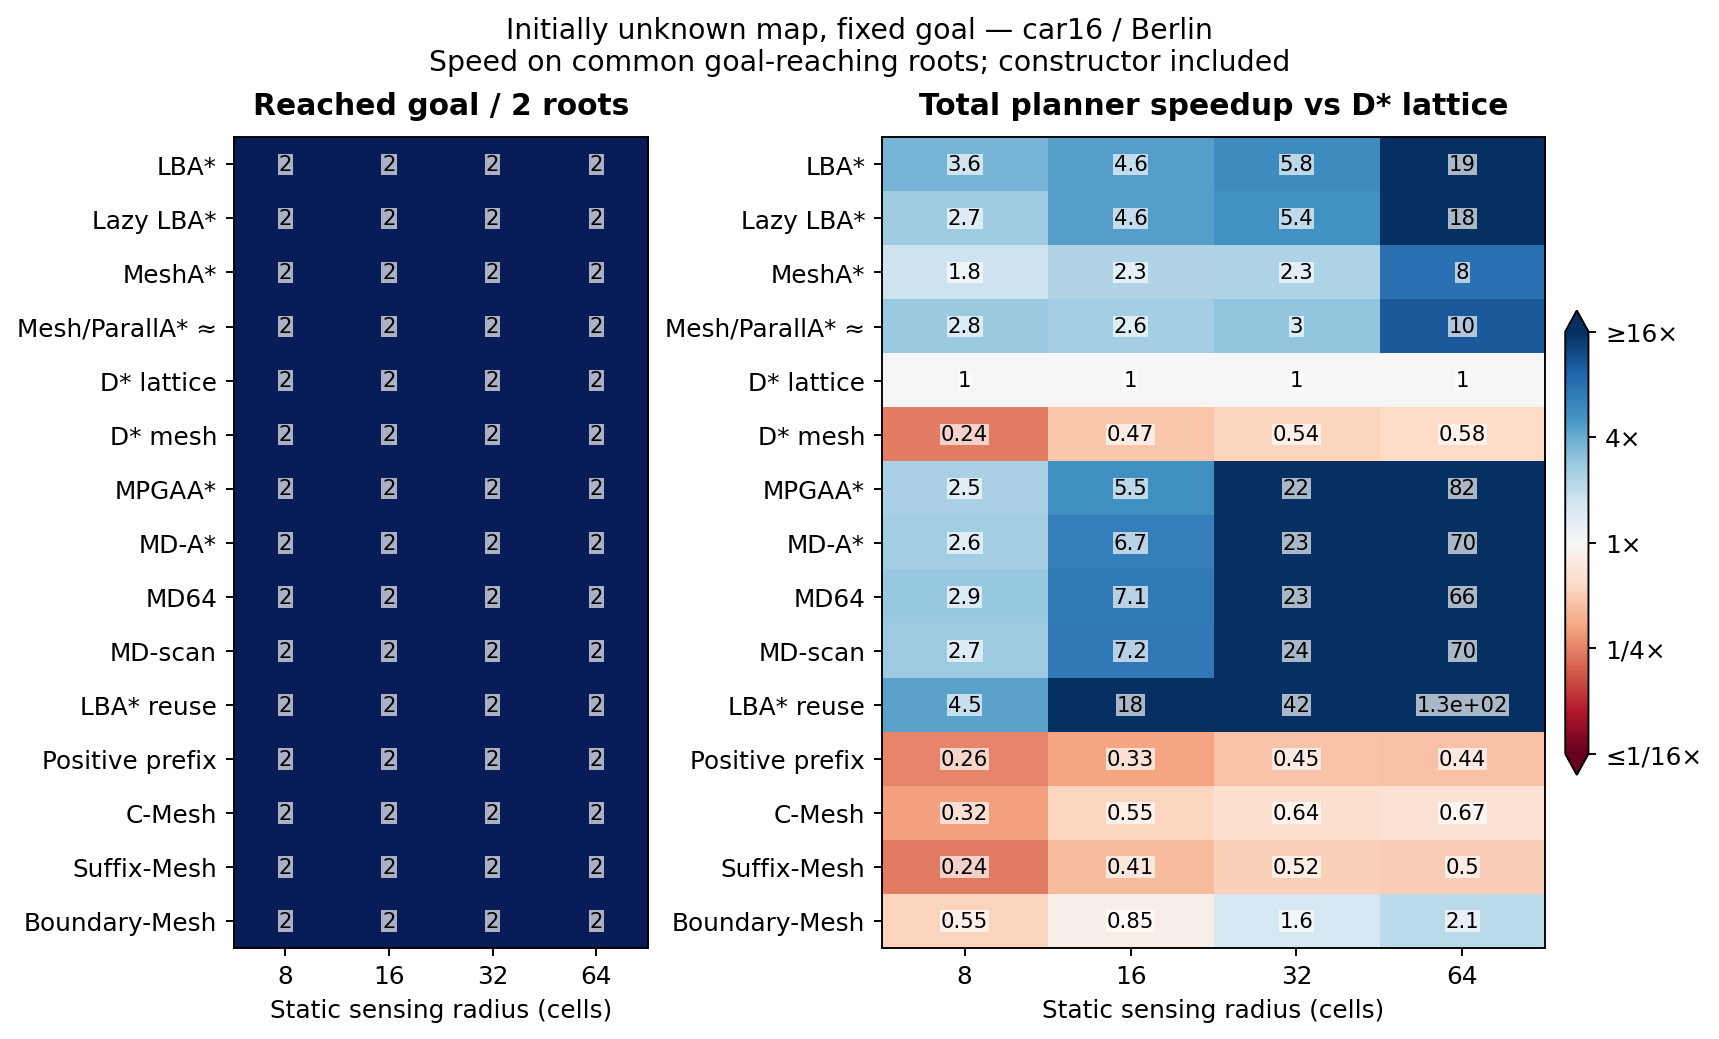

In [3]:
static = pd.read_csv(directory/'static_radius.csv')
display(static[static['map'].eq('Berlin')].pivot(index='method',columns='radius',values=['goals','episode_s','expansions']))
display(Image(filename=str(root/'docs/experiments/navigation_figures/static_Berlin.png')))

paired_online                          online_speedup                      \
cr            1    5    10   15   20   30             1         5         10   
k                                                                              
2            2.0  2.0  2.0  2.0  2.0  2.0       0.187048  0.129450  0.187770   
4            2.0  2.0  2.0  2.0  2.0  2.0       0.189320  0.146113  0.133003   
8            2.0  2.0  2.0  2.0  2.0  2.0       0.161254  0.139402  0.161908   
16           2.0  2.0  2.0  2.0  2.0  2.0       0.174400  0.151831  0.135294   
32           2.0  2.0  2.0  2.0  2.0  2.0       0.204900  0.178247  0.181728   
64           2.0  2.0  2.0  2.0  2.0  2.0       0.298654  0.223175  0.212720   

                                  
cr        15        20        30  
k                                 
2   0.151033  0.185510  0.167476  
4   0.129879  0.166398  0.161553  
8   0.165646  0.134376  0.138067  
16  0.155655  0.176110  0.149656  
32  0.190885  0.174286  0.181025  
64  0.251108  0.238771  0.290766

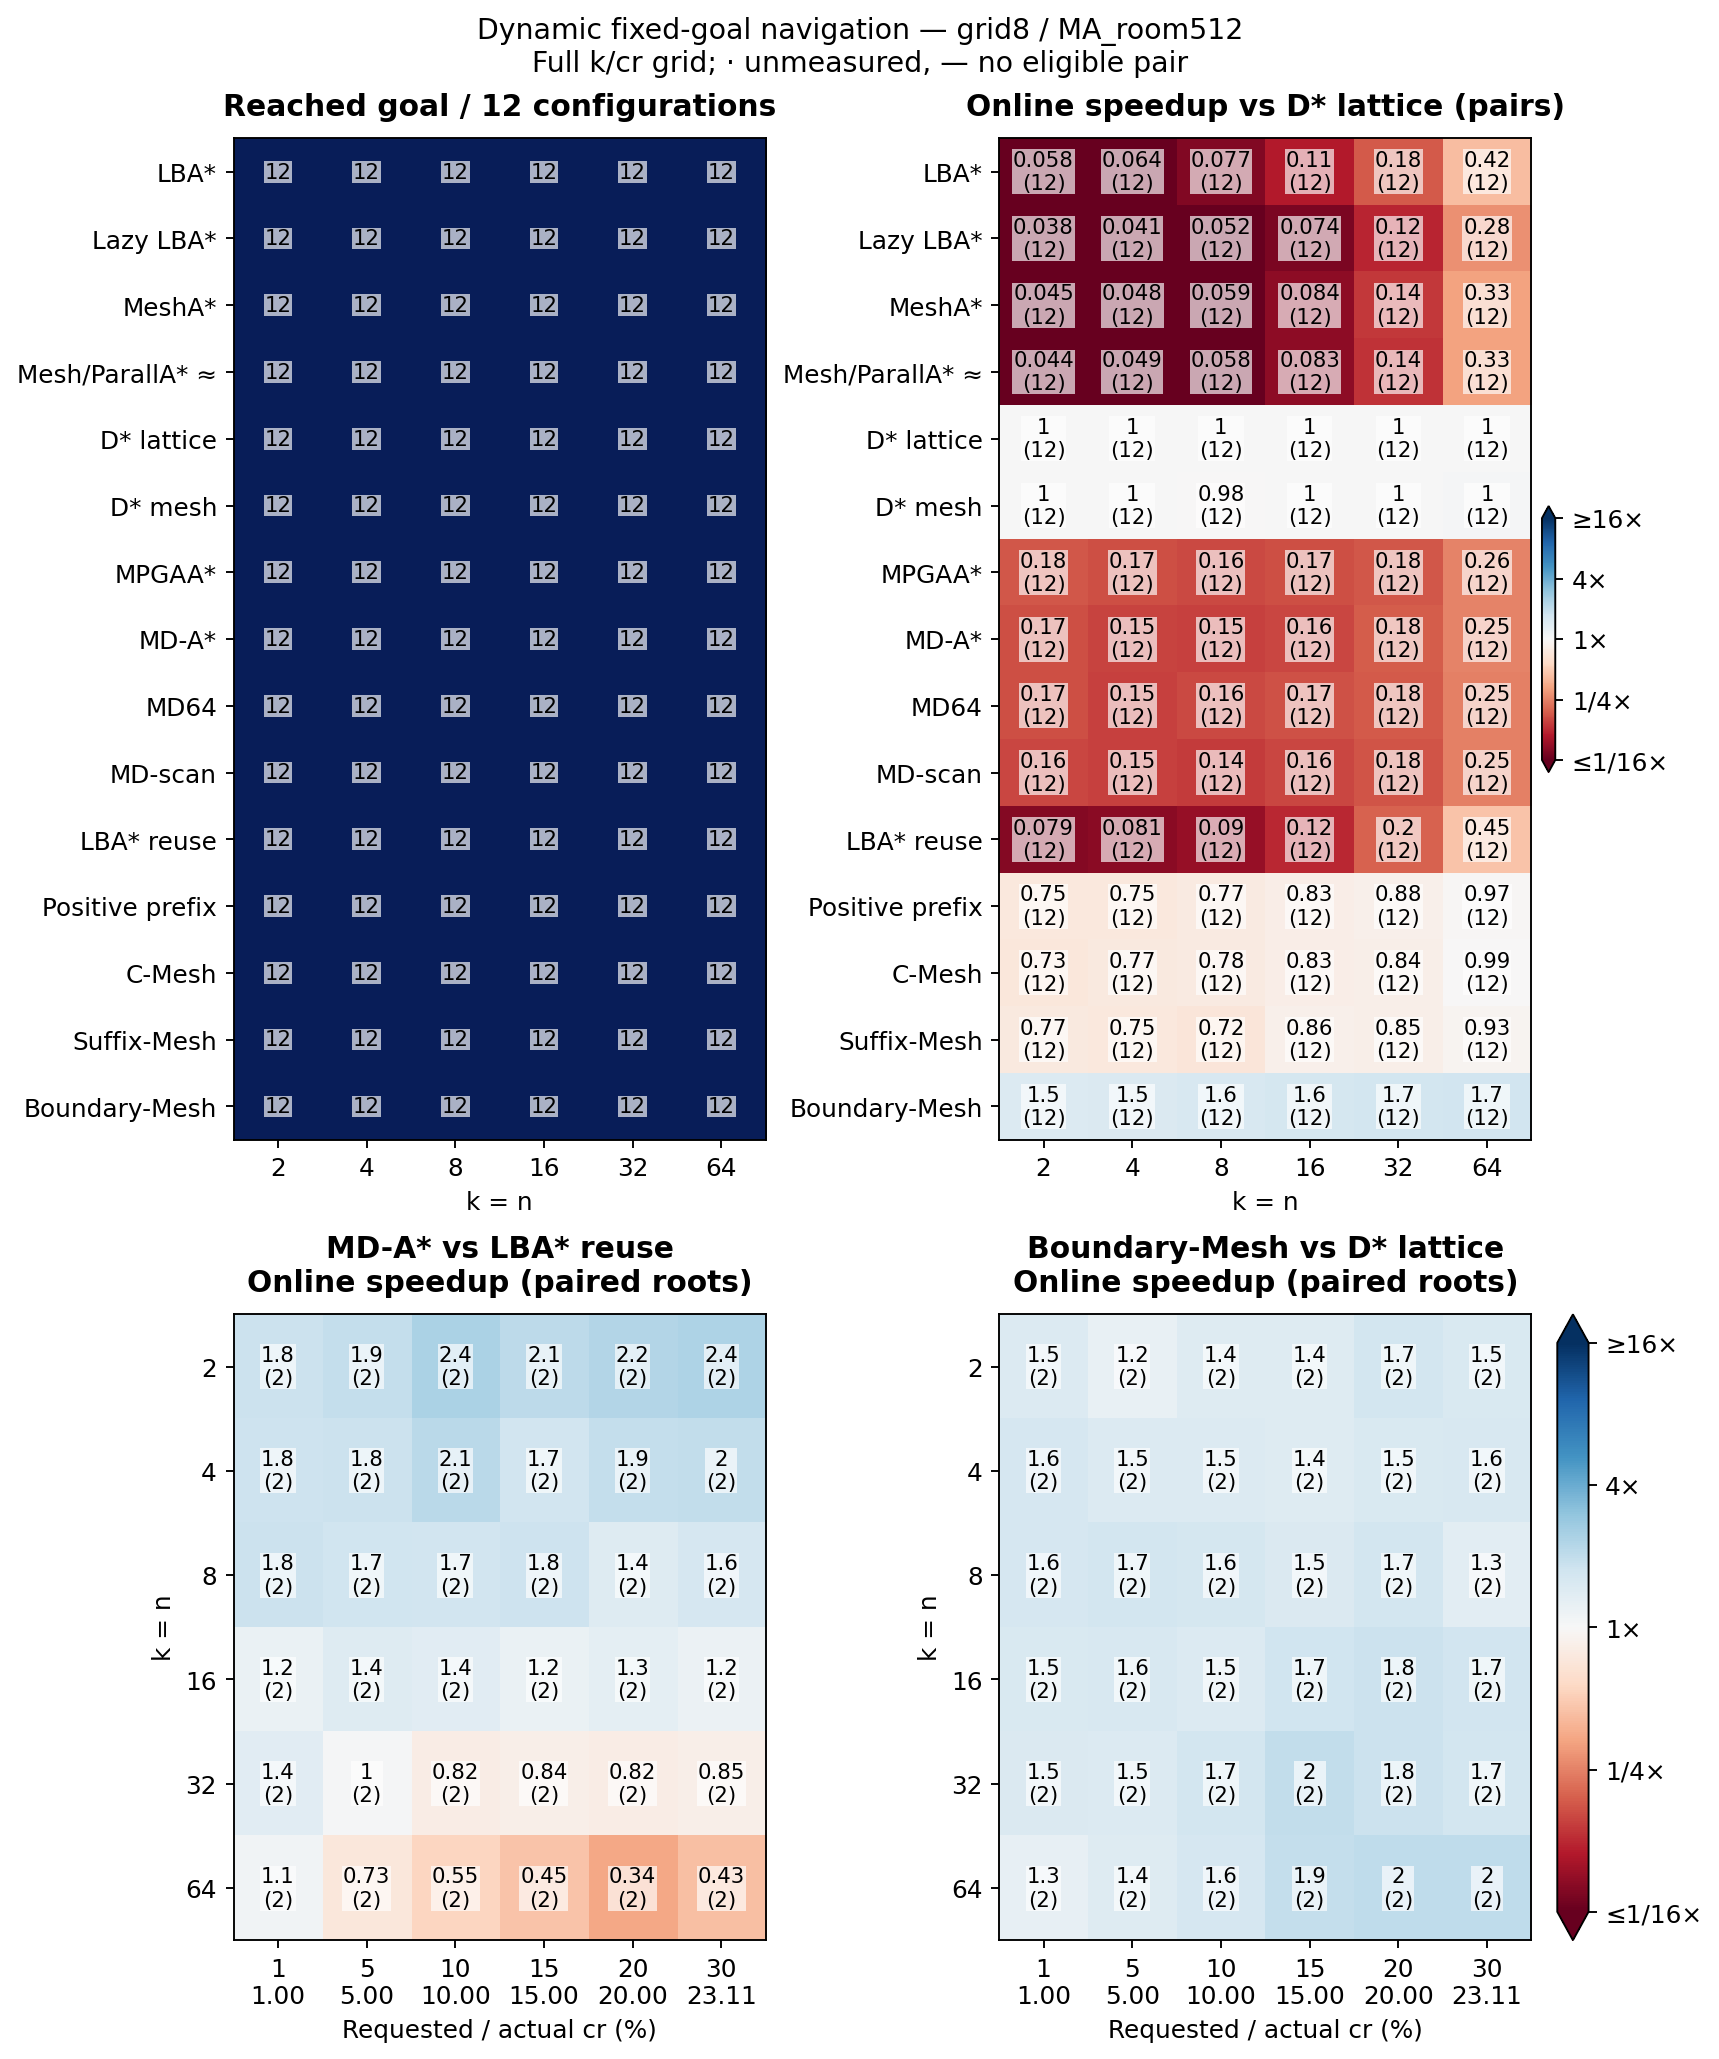

In [4]:
pairs = pd.read_csv(directory/'dynamic_pairs.csv')
view = pairs[pairs.control.eq('grid8') & pairs['map'].eq('MA_room512') & pairs.method.eq('md_astar') & pairs.baseline.eq('dstar_lattice')]
display(view.pivot(index='k',columns='cr',values=['paired_online','online_speedup']))
display(Image(filename=str(root/'docs/experiments/navigation_figures/dynamic_grid8_MA_room512.png')))

In [5]:
dynamic = episodes[episodes.kind.eq('dynamic') & episodes.phases.gt(0)]
display(dynamic.groupby(['control','map','cr']).agg(actual_cr=('actual_cr','median'),clamped_phases=('clamped_phases','sum'),episodes=('case','size')).reset_index())

,control,map,cr,actual_cr,clamped_phases,episodes
0,car16,AR0700,5,5.000000,0.0,30
1,car16,AR0700,10,10.000000,0.0,30
2,car16,AR0700,20,20.000000,0.0,15
3,car16,Berlin,5,4.998779,0.0,30
4,car16,Berlin,10,10.000610,0.0,30
...,...,...,...,...,...,...
71,grid8,random50_p40,5,5.040000,0.0,150
72,grid8,random50_p40,10,10.000000,0.0,150
73,grid8,random50_p40,15,15.040000,0.0,150
74,grid8,random50_p40,20,20.000000,0.0,150


In [6]:
work = pd.read_csv(directory/'work_by_observed_changes.csv')
display(work[work['map'].eq('MA_random512') & work.control.eq('grid8') & work.method.isin(['lba_reuse','dstar_lattice','md_astar','boundary_mesh'])])

,control,map,method,change_bin,queries,median_ms,p95_ms,expansions,checked_cells,notify_probes
861,grid8,MA_random512,boundary_mesh,1,1579,0.116946,0.425287,0.0,73.0,9.0
862,grid8,MA_random512,boundary_mesh,2–4,4267,0.122275,0.400733,0.0,154.0,27.0
863,grid8,MA_random512,boundary_mesh,5–16,5253,0.147653,0.450716,1.0,357.0,72.0
864,grid8,MA_random512,boundary_mesh,17–64,2983,0.219310,0.827812,2.0,653.0,234.0
865,grid8,MA_random512,boundary_mesh,65–256,165,0.932535,2.003532,22.0,5586.0,1503.0
866,grid8,MA_random512,boundary_mesh,257–1024,62,3.556112,5.945600,98.0,17337.5,7281.0
867,grid8,MA_random512,boundary_mesh,>1024,26,9.588521,17.170868,458.0,39232.5,23049.0
875,grid8,MA_random512,dstar_lattice,1,1579,0.154613,0.725474,0.0,8.0,0.0
876,grid8,MA_random512,dstar_lattice,2–4,4267,0.169945,0.692558,0.0,16.0,0.0
877,grid8,MA_random512,dstar_lattice,5–16,5253,0.234702,0.741316,0.0,51.0,0.0


In [7]:
prior = pd.read_csv(directory/'prior_by_map.csv')
display(prior[prior.cohort.eq('contemporary15') & prior.control.eq('car16') & prior['map'].eq('Berlin') & prior['mode'].eq('replay')].pivot(index='method',columns='family',values=['completed','online_s']))

completed                                  online_s            \
family              churn off_path on_path unknown_replay     churn  off_path   
method                                                                          
boundary_mesh         2.0      2.0     2.0            2.0  0.056848  0.006409   
cmesh_dstar           2.0      2.0     1.0            2.0  0.065089  0.013804   
dstar_lattice         2.0      2.0     2.0            2.0  0.213638  0.012263   
dstar_mesh            2.0      2.0     1.0            2.0  0.252324  0.011763   
lazy_lba              2.0      2.0     2.0            2.0  3.100632  0.016879   
lba                   2.0      2.0     2.0            2.0  1.874888  0.017263   
lba_reuse             2.0      2.0     2.0            2.0  1.776277  0.000013   
md64                  1.0      2.0     2.0            2.0  0.004637  0.000063   
md_astar              1.0      2.0     2.0            2.0  0.005420  0.000065   
md_scan               1.0      2.0     2.0            2.0  0.004653  0.000063   
mesh_parall           1.0      2.0     2.0            2.0  0.067283  0.034521   
mesha                 1.0      2.0     2.0            2.0  0.083481  0.045007   
mpgaa                 2.0      2.0     2.0            2.0  3.378588  0.000125   
prefix_positive       2.0      2.0     1.0            2.0  0.087507  0.019157   
suffix_mesh           2.0      2.0     1.0            2.0  0.080983  0.014879   

                                           
family             on_path unknown_replay  
method                                     
boundary_mesh    12.498520       0.114009  
cmesh_dstar       0.051145       0.267567  
dstar_lattice     7.043391       0.074085  
dstar_mesh        0.065533       0.355957  
lazy_lba          0.011836       0.021564  
lba               0.011235       0.021735  
lba_reuse         0.010871       0.003712  
md64              0.008975       0.012630  
md_astar          0.009223       0.010160  
md_scan           0.009081       0.012498  
mesh_parall       0.021477       0.045115  
mesha             0.029041       0.060549  
mpgaa             0.009228       0.013070  
prefix_positive   0.063025       0.368812  
suffix_mesh       0.057205       0.331736

In [8]:
display(episodes[episodes.repeats.eq(3)].groupby(['control','kind']).agg(configurations=('case','size'),median_relative_mad=('repeat_relative_mad','median')))
display({k:audit[k] for k in ['repeat_decision_parity','grid_mesh_projection_parity','manifest_sha256','selection_sha256','verification_sha256']})

configurations  median_relative_mad
control kind                                        
car16   dynamic             720             0.021309
        unknown             720             0.018587
grid8   dynamic            1200             0.018180

{'repeat_decision_parity': 'passed',
 'grid_mesh_projection_parity': 'passed',
 'manifest_sha256': '2bdaaabfe163a61d3d0acdc08cfbfd57d0492ef74997b4481cca798ea55d596d',
 'selection_sha256': 'cfce8f607439448317350964a3c721d9290a46107568fcf58eaa6d03d3bcf2a2',
 'verification_sha256': 'c976755a736f82874740d5b3ffa0682cd1bc4066bdbea34850027d92581f840e'}

Полные остановки, сырые времена, хеши и воспроизводимые команды сохранены в артефакте. Отдельный контроль с октильным A* и Octile A* reuse, где вместе повторно измерены LBA* reuse, MPGAA* и MD-A*, приведён в `navigation.pdf` и `cpp/navigation_controls/results/full/analysis/`. Его времена сравниваются внутри собственной серии. Один широкий временной повтор вне четырёх опорных точек и два корня на карту ограничивают статистические выводы. Отношение длины динамического пути к начальному оптимуму не является competitive ratio.